In [5]:
# Install required external packages
!pip install pandas numpy matplotlib scikit-learn

In [6]:
import os
import glob
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings

In [7]:
# 1. Get list of CSV files (modify folder name if needed)
data_folder = os.path.join(os.getcwd(), "../data")
csv_files = glob.glob(os.path.join(data_folder, "smart_meter_data_*.csv"))
print("Found files:", csv_files)

# 2. Load each CSV into a DataFrame
dataframes = [pd.read_csv(file) for file in csv_files]


Found files: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_0.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_1.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_2.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_3.csv']


In [ ]:
import pandas as pd

def preprocess_df(dataframes):
    """
    Preprocess a list of DataFrames:
      - Print missing values per column.
      - Convert the 'time' column to datetime with UTC conversion.
      - Remove timezone info, sort the DataFrame by 'time' and reset the index.
      - Drop the 'id' column if present.
      - Create new time-related features: hour, minute, second, day, and month.
    """
    processed = []
    for idx, df in enumerate(dataframes, start=1):
        print(f"\nDataFrame {idx}:")
        
        # Print missing value percentages and column names.
        missing_pct = df.isnull().mean() * 100
        print("Percentage of missing values per column:")
        print(missing_pct)
        print("Columns in DataFrame:")
        print(df.columns.tolist())
        
        # Convert 'time' column to datetime with UTC conversion.
        df['time'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
        if df['time'].isnull().any():
            print("Warning: Some 'time' values could not be converted and are NaT!")
        # Remove timezone information (naive datetime)
        df['time'] = df['time'].dt.tz_convert(None)
        df.sort_values('time', inplace=True)
        df.reset_index(drop=True, inplace=True)
        
        # Drop the 'id' column if it exists.
        if 'id' in df.columns:
            df = df.drop(columns=['id'])
        
        # Create time-based features.
        df['hour'] = df['time'].dt.hour
        df['minute'] = df['time'].dt.minute
        df['second'] = df['time'].dt.second
        df['day'] = df['time'].dt.day
        df['month'] = df['time'].dt.month
        
        processed.append(df)
    return processed

def concat_dataframes_by_time(dataframes):
    """
    Concatenate a list of DataFrames into a single DataFrame and order the rows by 'time'.
    """
    combined_df = pd.concat(dataframes, ignore_index=True)
    combined_df['time'] = pd.to_datetime(combined_df['time'], errors='coerce')
    combined_df.sort_values('time', inplace=True)
    combined_df.reset_index(drop=True, inplace=True)
    return combined_df

def get_complete_time_series(df):
    """
    Group the concatenated DataFrame by device_id and serial_number,
    then return a list of groups (DataFrames) that have no missing values.
    """
    complete_series = []
    grouped = df.groupby(['device_id', 'serial_number'])
    for (device, serial), group in grouped:
        # Ensure the group is sorted by time.
        group_sorted = group.sort_values('time')
        # Skip groups with any missing data.
        if group_sorted.isnull().any().any():
            print(f"Skipping time series for device_id: {device}, serial_number: {serial} due to missing data.")
            continue
        complete_series.append(group_sorted)
    return complete_series

def add_lag_features(df, columns, lag_freqs={'lag_1h':'1H', 
                                             'lag_12h':'12H', 
                                             'lag_24h':'24H', 
                                             'lag_1w':'7D'}):
    # add 48h lag
    # 12h lag does not give info
    


    """
    Add lag features for the specified columns based on time differences.
    - First, adds a simple one-row lag.
    - Then, adds time-based lags using pd.merge_asof for given lag frequencies.
    """
    # Create a copy of the DataFrame to avoid modifying the original data.
    df = df.copy()
    
    # Ensure that the 'time' column is converted to datetime format.
    # If there are errors during conversion, they are coerced to NaT (Not a Time).
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    
    # Sort the DataFrame by the 'time' column in ascending order.
    df.sort_values('time', inplace=True)
    
    # ---------------------------
    # Simple one-row lag: Shift each specified column by 1 row.
    # This creates a feature representing the previous value for each column.
    for col in columns:
        df[f'{col}_lag_1'] = df[col].shift(1)
    
    # ---------------------------
    # Time-based lags using pd.merge_asof:
    # For each defined lag frequency (e.g., 1 hour, 12 hours, etc.), create lagged features.
    for suffix, lag_str in lag_freqs.items():
        # Convert the lag string (e.g., '1H') to a Timedelta object.
        lag_delta = pd.Timedelta(lag_str)
        
        # Create a new column 'time_shift_{suffix}' by subtracting the lag delta from the 'time' column.
        # This column represents the target time we want to look back from.
        df[f'time_shift_{suffix}'] = df['time'] - lag_delta
        
        # Create a temporary DataFrame that includes the original 'time' and the columns for which we want lag features.
        temp = df[['time'] + columns].copy()
        
        # Rename the columns in the temporary DataFrame to include the lag suffix.
        # This helps differentiate the lagged features from the original ones.
        rename_dict = {col: f'{col}_{suffix}' for col in columns}
        temp.rename(columns=rename_dict, inplace=True)
        
        # Use pd.merge_asof to merge the original DataFrame with the temporary DataFrame containing lagged values.
        # This performs an as-of merge, aligning rows based on the nearest (backward) time match.
        merged = pd.merge_asof(
            # Sort the original DataFrame by the shifted time column (e.g., "time_shift_lag_1h").
            # This column represents the 'time' values shifted back by the lag interval.
            df.sort_values(f'time_shift_{suffix}'),
            
            # Sort the temporary DataFrame by its 'time' column.
            # This DataFrame holds the lagged values with new column names.
            temp.sort_values('time'),
            
            # Specify the left key for merging: the shifted time column in the original DataFrame.
            left_on=f'time_shift_{suffix}',
            
            # Specify the right key for merging: the actual 'time' column in the temporary DataFrame.
            right_on='time',
            
            # Set the merge direction to 'backward' so that for each row in df, the merge returns the most recent row in temp
            # that does not exceed the shifted time.
            direction='backward',
            
            # Set a tolerance to ensure that only rows within the specified lag interval (converted from lag_str) are merged.
            tolerance=pd.Timedelta(lag_str)  # Only merge if the time difference is within the lag window.
        )
        
        # For each specified column, extract the corresponding lagged value from the merged DataFrame
        # and assign it back to the original DataFrame with the appropriate suffix.
        for col in columns:
            df[f'{col}_{suffix}'] = merged[f'{col}_{suffix}'].values
        
        # Remove the temporary shifted time column from the original DataFrame as it's no longer needed.
        df.drop(columns=[f'time_shift_{suffix}'], inplace=True)
    
    # Return the DataFrame augmented with both simple and time-based lag features.
    return df

# ---------------------------
# Main Processing Workflow
# ---------------------------
#
# 1. Preprocess each DataFrame.
processed_dfs = preprocess_df(dataframes)

# 2. Concatenate the processed DataFrames by time.
data_concat = concat_dataframes_by_time(processed_dfs)

# 3. Drop the column with 100% missing values (e.g., 'values_state').
data_concat.drop(columns='values_state', inplace=True, errors='ignore')

# 4. Group the data by device_id and serial_number, extracting only complete time series.
complete_time_series = get_complete_time_series(data_concat)
print(f"Number of complete time series: {len(complete_time_series)}")

# 5. Define the columns for which to add lag features.
columns_to_add_lag = [
    'total_power_active', 'total_power_reactive', 'total_power_apparent',
    'import_energy_active', 'export_energy_active',
    'import_energy_reactive', 'export_energy_reactive',
    'total_energy_active', 'total_energy_reactive'
]

# 6. For each complete time series, apply lag feature engineering.
processed_time_series = []
for ts in complete_time_series:
    ts_lagged = add_lag_features(ts, columns_to_add_lag)
    processed_time_series.append(ts_lagged)

print(f"Processed {len(processed_time_series)} time series with lag features.")

# Optionally, concatenate all processed time series into a single DataFrame for further analysis.
data_final = pd.concat(processed_time_series).reset_index(drop=True)
data_final.sort_values(by=['device_id', 'serial_number', 'time'], inplace=True)

print("Final data processing complete. Ready for feature engineering.")



DataFrame 1:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
total_power_reactive        0.0
total_power_apparent        0.0
import_energy_active        0.0
export_energy_active        0.0
import_energy_reactive      0.0
export_energy_reactive      0.0
total_energy_active         0.0
total_energy_reactive       0.0
dtype: float64
Columns in DataFrame:
['time', 'device_id', 'serial_number', 'values_state', 'total_power_active', 'total_power_reactive', 'total_power_apparent', 'import_energy_active', 'export_energy_active', 'import_energy_reactive', 'export_energy_reactive', 'total_energy_active', 'total_energy_reactive']

DataFrame 2:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
tota

C:\Users\stros\AppData\Local\Temp\ipykernel_27544\3831709529.py:103: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  lag_delta = pd.Timedelta(lag_str)
C:\Users\stros\AppData\Local\Temp\ipykernel_27544\3831709529.py:139: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  tolerance=pd.Timedelta(lag_str)  # Only merge if the time difference is within the lag window.
C:\Users\stros\AppData\Local\Temp\ipykernel_27544\3831709529.py:103: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  lag_delta = pd.Timedelta(lag_str)
C:\Users\stros\AppData\Local\Temp\ipykernel_27544\3831709529.py:139: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  tolerance=pd.Timedelta(lag_str)  # Only merge if the time difference is within the lag window.
C:\Users\stros\AppData\Local\Temp\ipyk

Processed 39 time series with lag features.
Final data processing complete. Ready for feature engineering.


In [9]:
for ts in processed_time_series:
    print(ts)

                           time                             device_id  \
34      2023-12-31 23:01:00.000  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
75      2023-12-31 23:06:00.094  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
116     2023-12-31 23:11:00.274  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
157     2023-12-31 23:16:00.551  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
198     2023-12-31 23:20:59.565  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
...                         ...                                   ...   
4257440 2024-12-31 22:35:36.182  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
4257481 2024-12-31 22:40:36.128  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
4257522 2024-12-31 22:45:36.141  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
4257563 2024-12-31 22:50:36.175  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   
4257604 2024-12-31 22:55:36.198  114b44b0-0dc4-45d6-a4ac-83223ea9b2d8   

                                serial_number  total_power_active  \
34       960bf15f-a847-49de-9648-45db048f3cf8         

Time Series 1: Total samples = 101279, Initial training samples = 101
[[ 85.71054945 119.00680942 144.70004636 ...  58.96558203 581.94648452
  199.08801433]
 [ 81.72894628 117.5532654  144.92287259 ...  59.83148416 576.66944722
  193.42834242]
 [ 83.83729633 117.14822255 140.50532392 ...  61.99231206 571.02267837
  187.59814256]
 ...
 [ 84.75539195 117.86233819 139.26668508 ...  61.07121735 587.72678758
  193.32891907]
 [ 83.78557659 119.24832294 145.015087   ...  61.07121735 587.72678758
  193.32891907]
 [ 82.13698687 120.63462398 143.55951562 ...  58.61916441 580.48512146
  194.23775374]]
Time Series 1 - Batch 1: MSE = 326.1018, R^2 = 0.6902


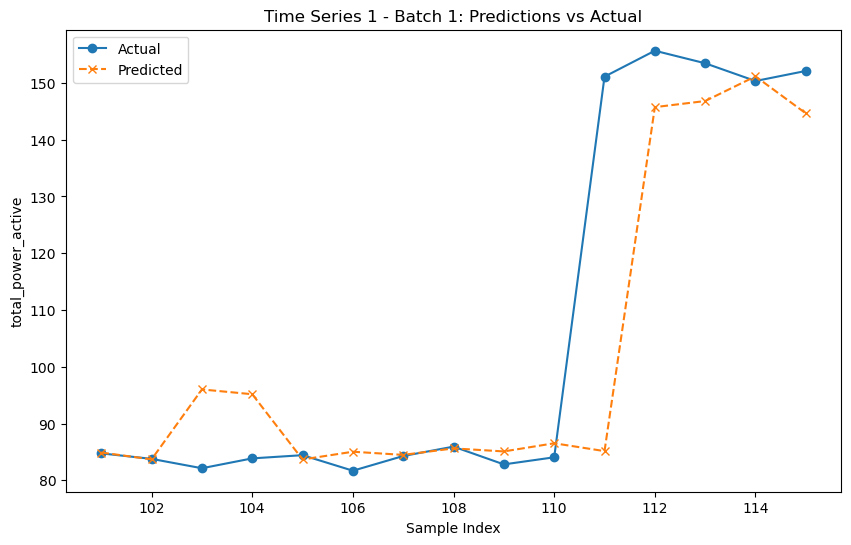

[[  83.87317925  117.64225861  142.719033   ...   59.51527876
   570.52741035  195.11716433]
 [  84.43750344  119.55376991  142.22348458 ...   59.00159949
   570.82876078  195.95486347]
 [  81.69944923  115.17033908  140.25690474 ...   60.89955678
   579.67957739  191.77056278]
 ...
 [  82.03880279  113.03696204  135.56994524 ...   58.75696054
   558.98470218  193.78862632]
 [ 827.4611231   201.85918627  933.48331456 ...   60.16999507
   593.20717847  195.94163986]
 [1196.18473903  196.95031132 1290.50704866 ...   60.28160859
   575.19502484  198.81741626]]
Time Series 1 - Batch 2: MSE = 111843.1215, R^2 = -0.0982


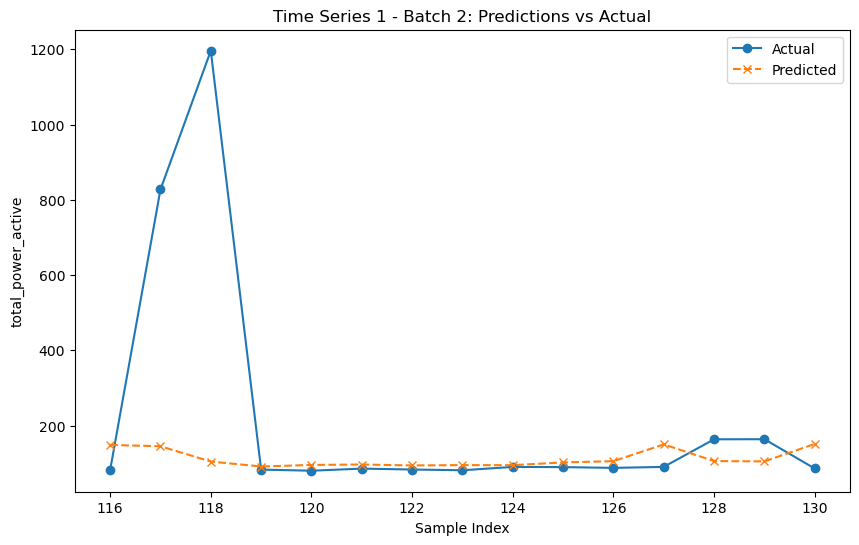

[[ 83.11897527 118.83960872 139.63177207 ...  59.29102679 581.5280595
  193.32349581]
 [ 80.12065432 117.42464663 138.6011561  ...  59.29102679 581.5280595
  193.32349581]
 [ 85.71755481 119.2460992  136.92685006 ...  60.80958891 581.69390222
  191.60894602]
 ...
 [ 90.50237645 119.93542263 149.04888027 ...  61.03625999 563.57689961
  193.28874578]
 [ 89.23808427 122.04523876 142.47811393 ...  60.13665041 571.00089573
  199.86206163]
 [ 84.98322341 119.18798561 142.83271269 ...  60.01526792 571.1750341
  196.96937505]]
Time Series 1 - Batch 3: MSE = 556.1801, R^2 = -0.0044


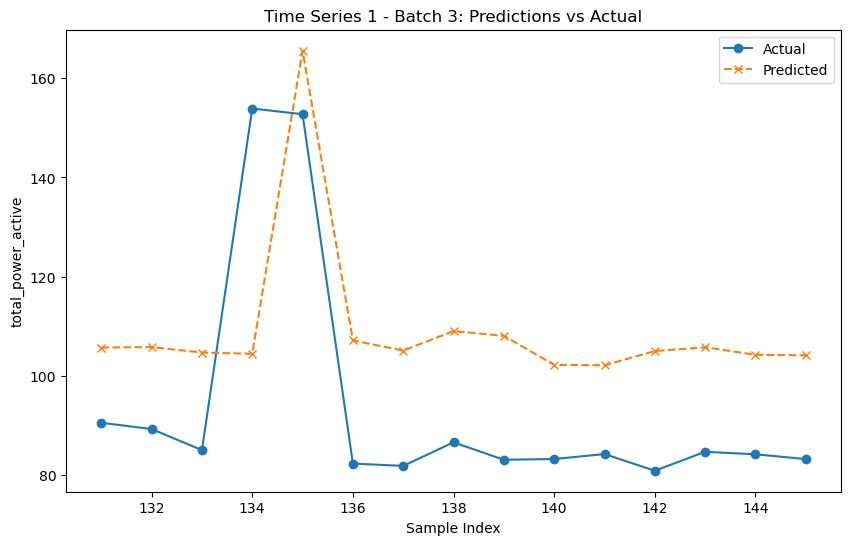

[[153.90055523 110.53313898 218.24398676 ...  60.01526792 571.1750341
  196.96937505]
 [152.75833753 115.73578875 216.11390623 ...  59.69659421 572.50356022
  190.47786828]
 [ 82.27089368 119.41532814 135.63197124 ...  59.69659421 572.50356022
  190.47786828]
 ...
 [ 82.9108474  118.92310873 142.55335734 ...  59.67333274 579.90112423
  191.77842271]
 [ 83.30980888 116.47805807 140.10842463 ...  59.90894915 563.55741559
  194.94194441]
 [ 81.06896633 121.419028   142.42054007 ...  60.72395405 574.19159331
  194.86430441]]
Time Series 1 - Batch 4: MSE = 379.7571, R^2 = -224.0172


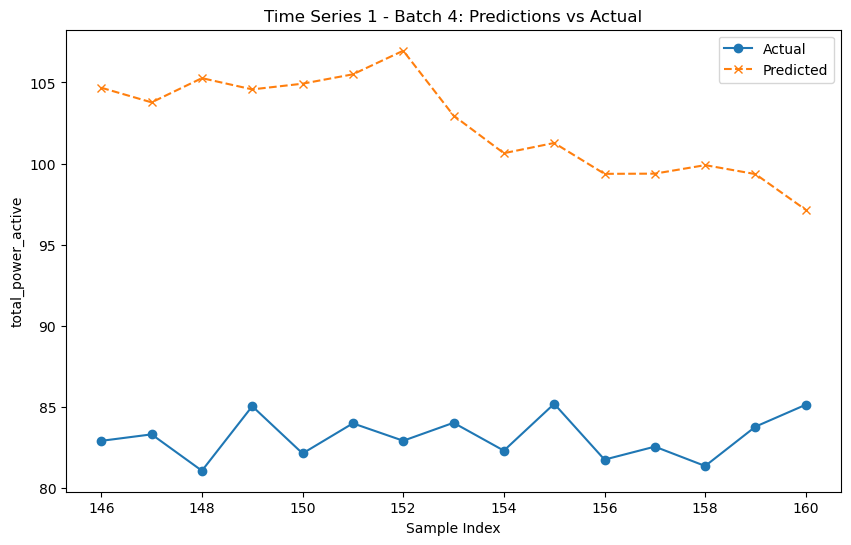

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

def create_supervised_data_from_series(df, input_features, target_feature, window_size=3):
    """
    Create a supervised learning dataset from a time series DataFrame.
    
    For each time step t (starting at t = window_size), the input X is created by 
    flattening the values of the specified input_features from times t-window_size to t-1,
    and the target y is the value of target_feature at time t.
    
    Parameters:
        df (pd.DataFrame): Time series data (assumed sorted by time).
        input_features (list): List of feature column names to include as inputs.
        target_feature (str): Column name of the target variable.
        window_size (int): Number of past observations to include.
    
    Returns:
        X (np.ndarray): 2D array with shape (n_samples, window_size * n_features).
        y (np.ndarray): 1D array with the target values.
    """
    X, y = [], []
    for i in range(window_size, len(df)):
        # Flatten the window of input features into a single vector.
        window_data = df.iloc[i-window_size:i][input_features].values.flatten()
        X.append(window_data)
        y.append(df.iloc[i][target_feature])
    return np.array(X), np.array(y)

# ---------------------------
# Parameters for the experiment
# ---------------------------
window_size = 12          # Sliding window length (number of past observations used)
target_feature = 'total_power_active'  # The target variable to forecast
n_series_to_train = 1     # Number of time series to work with (from your processed list)
training_ratio = 0.001     # Use the first 40% of the supervised data for initial training
batch_size = 15           # Number of samples in each incremental prediction batch
num_batches = 4           # Number of incremental batches to process

# ---------------------------
# Prepare the supervised dataset from selected time series
# ---------------------------
# Assume processed_time_series is a list of complete time series DataFrames
# (each with the same structure) produced from previous preprocessing.
all_columns = processed_time_series[0].columns.tolist()
# Use all features except identifiers (like 'time', 'device_id', 'serial_number').
input_features = [col for col in all_columns if col not in ['time', 'device_id', 'serial_number']]

# Process each selected time series incrementally.
for ts_idx, ts in enumerate(processed_time_series[:n_series_to_train]):
    ts = ts.sort_values('time')  # Ensure the series is in chronological order
    # Create supervised data using the sliding window approach.
    X_ts, y_ts = create_supervised_data_from_series(ts, input_features, target_feature, window_size)
    
    # ---------------------------------------------------------
    # Drop rows where X_ts has NaNs (if any) to avoid incomplete data.
    valid = ~np.isnan(X_ts).any(axis=1)
    X_ts = X_ts[valid]
    y_ts = y_ts[valid]
    # ---------------------------------------------------------
    
    total_samples = len(X_ts)
    # Determine the initial training cutoff (first 40% of samples)
    n_train = int(training_ratio * total_samples)
    
    print(f"Time Series {ts_idx+1}: Total samples = {total_samples}, Initial training samples = {n_train}")
    
    # Initial training data (only using past samples).
    X_train = X_ts[:n_train]
    y_train = y_ts[:n_train]
    
    # Also drop any NaNs from the initial training set, if present.
    valid_train = ~np.isnan(X_train).any(axis=1)
    X_train = X_train[valid_train]
    y_train = y_train[valid_train]

    # Ensure no data leakage: train only on past data.
    model = GradientBoostingRegressor(random_state=42)
    model.fit(X_train, y_train)
    
    # Process incremental batches.
    for batch in range(num_batches):
        # Determine the batch indices: each batch is the next batch_size samples.
        batch_start = n_train + batch * batch_size
        batch_end = batch_start + batch_size
        
        # If there are not enough samples remaining for a full batch, break.
        if batch_end > total_samples:
            print(f"Not enough samples for batch {batch+1} in time series {ts_idx+1}.")
            break
        
        # Define the current test batch.
        X_batch = X_ts[batch_start:batch_end]
        y_batch = y_ts[batch_start:batch_end]
        
        # Drop rows with NaNs from the current batch (if any).
        valid_test = ~np.isnan(X_batch).any(axis=1)
        X_batch = X_batch[valid_test]
        y_batch = y_batch[valid_test]

        print(X_batch)

        
        # Predict on the current batch.
        y_pred_batch = model.predict(X_batch)
        
        # Evaluate the batch performance.
        mse_batch = mean_squared_error(y_batch, y_pred_batch)
        r2_batch = r2_score(y_batch, y_pred_batch)
        print(f"Time Series {ts_idx+1} - Batch {batch+1}: MSE = {mse_batch:.4f}, R^2 = {r2_batch:.4f}")
        
        # Plot the results for this batch.
        plt.figure(figsize=(10, 6))
        plt.plot(range(batch_start, batch_end), y_batch, label="Actual", marker='o')
        plt.plot(range(batch_start, batch_end), y_pred_batch, label="Predicted", marker='x', linestyle='--')
        plt.title(f"Time Series {ts_idx+1} - Batch {batch+1}: Predictions vs Actual")
        plt.xlabel("Sample Index")
        plt.ylabel(target_feature)
        plt.legend()
        plt.show()
        
        # Optional: Update training data with the current batch for incremental learning.
        # Uncomment the following lines to simulate model updating with new data:
        # X_train = np.vstack([X_train, X_batch])
        # y_train = np.concatenate([y_train, y_batch])
